# EfficientNetB0 (Chris Deotte starter, LB 0.43) — local reproduction + fair comparison

Source recipe: https://www.kaggle.com/code/cdeotte/efficientnetb0-starter-lb-0-43
(+ his "How To Make Spectrogram from EEG" notebook for the EEG spectrograms).

**Training recipe — unchanged from the original:**
- One training row per `eeg_id`: votes summed over all its sub-windows, normalised; window =
  mean of min/max spectrogram offsets (`r = (min+max)//4`).
- Input 128×256×8: 4 Kaggle spectrograms (LL, RL, LP, RP; clip → log → standardise → crop, ÷2)
  + 4 EEG mel-spectrograms of the **middle 50 s** of each EEG (his `spectrogram_from_eeg`).
- 8 channels tiled into 512×512, repeated ×3 → **`efficientnet` package** EfficientNetB0 with ImageNet
  (AutoAugment) weights → GAP → Dense(6, softmax). No input rescaling inside the backbone.
- Adam, KL-divergence loss, 4 epochs, LR 1e-3, 1e-3, 1e-4, 1e-5, batch 32, auto mixed precision.

**What changed vs the previously saved notebook (`/workspace` version):**

| # | Change | Why |
|---|---|---|
| 1 | Backbone: `efficientnet.tfkeras.EfficientNetB0` (as Chris) instead of `tf.keras.applications.EfficientNetB0` | Keras' version divides inputs by 255 and applies ImageNet mean/std internally; spectrogram inputs (≈±1) became a near-constant image → unstable val loss (4.3, 8.4 spikes) and poor KLD |
| 2 | Runs in TF 2.15 / Keras 2 env (`hms-effnet` kernel), same generation Kaggle used | `efficientnet` 1.1.1 needs Keras 2 |
| 3 | Folds: `FOLD_MODE='native'` = Chris' own GroupKFold on the 17,089-row table (his setup); `'csv'` = VIPEEGNet's split | run both: native = his setup, csv = isolates the split effect |
| 4 | Native CV uses the official competition KL metric (eps 1e-15, zero-target terms dropped) | matches Chris' printed CV |
| 5 | **Comparison patch (eval only, either split):** each fold model also predicts the VIPEEGNet validation rows whose patients it never trained on (20,183 rows total), each at its own label window | old "HQ = any segment ≥10 votes" used summed labels on a different row set → not comparable |
| 6 | Caches built in parallel, atomic writes; paths from `PROJECT_DIR`; smoke-test mode | speed, robustness |

## Parameters

In [1]:
PROJECT_DIR = '~/hms'
FOLD_MODE = 'csv'          # 'csv' = archived VIPEEGNet patient split (comparison) | 'native' = Chris' GroupKFold
AUGMENT = False            # Chris' starter trains with augment=False (HorizontalFlip p=0.5 path kept, off)
SMOKE_TEST = False         # True = ~250 patients, 2 epochs, fold 0 only
ROW_EVAL = True            # comparison patch: also predict the VIPEEGNet validation rows (works with either split)
EFFNET_WEIGHTS = '~/hms/pretrained/efficientnet-b0_weights_tf_dim_ordering_tf_kernels_autoaugment_notop.h5'
VIP_SPLIT = '~/hms/results/vipeegnet_groupkfold_v1/folds/patient_folds_groupkfold.csv'
N_WORKERS = 12
REQUIRE_GPU = True

In [2]:
# Parameters
PROJECT_DIR = "/home/nfs/jhb-dehzangi/ws04/gs1147/hms"
FOLD_MODE = "native"


In [3]:
import os, gc, time, json, warnings
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from joblib import Parallel, delayed
from sklearn.model_selection import GroupKFold
import tensorflow as tf
import efficientnet.tfkeras as efn
import librosa

gpus = tf.config.list_physical_devices('GPU')
print(f'TF {tf.__version__} | librosa {librosa.__version__} | GPUs: {gpus}')
assert gpus or not REQUIRE_GPU, 'TensorFlow cannot see the GPU — is the hms-effnet kernel selected?'
for g in gpus:
    tf.config.experimental.set_memory_growth(g, True)

# Chris: MIX = True -> auto mixed precision graph rewrite
tf.config.optimizer.set_experimental_options({'auto_mixed_precision': True})
SEED = 2024                     # Chris sets no seed; fixed here so reruns are comparable
np.random.seed(SEED); tf.random.set_seed(SEED)

P = os.path.abspath(os.path.expanduser(PROJECT_DIR))
DATA = f'{P}/hms-data'
EFFNET_WEIGHTS = os.path.expanduser(EFFNET_WEIGHTS)
VIP_SPLIT = os.path.expanduser(VIP_SPLIT)
KSPEC_CACHE = f'{P}/effnet_b0/kspec_cache'           # Kaggle spectrograms, one .npy per spectrogram_id
EEGSPEC_MID = f'{P}/effnet_b0/eegspec_mid_cache'     # Chris' EEG specs (middle 50 s), one per eeg_id
EEGSPEC_ROW = f'{P}/effnet_b0/eegspec_row_cache'     # EEG specs at each VIPEEGNet row's 50 s window
TAG = f'effnetb0_{"groupkfold" if FOLD_MODE == "csv" else "native"}' + ('_smoke' if SMOKE_TEST else '')
OUT = f'{P}/fair_comparison/{TAG}'
WDIR = f'{P}/effnet_b0/output/{TAG}'
for d in (KSPEC_CACHE, EEGSPEC_MID, EEGSPEC_ROW, OUT, WDIR):
    os.makedirs(d, exist_ok=True)
assert os.path.isfile(EFFNET_WEIGHTS), f'{EFFNET_WEIGHTS} missing — run setup_effnet_env.sh'

EPOCHS = 2 if SMOKE_TEST else 4
BATCH = 32
TARGETS = ['seizure_vote', 'lpd_vote', 'gpd_vote', 'lrda_vote', 'grda_vote', 'other_vote']
CLASS_NAMES = ['Seizure', 'LPD', 'GPD', 'LRDA', 'GRDA', 'Other']
print(f'TAG={TAG}\nOUT={OUT}')

TF 2.15.1 | librosa 0.10.1 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
TAG=effnetb0_native
OUT=/home/nfs/jhb-dehzangi/ws04/gs1147/hms/fair_comparison/effnetb0_native


## Data — Chris' eeg_id table (training) and the VIPEEGNet row table (evaluation)

In [4]:
df = pd.read_csv(f'{DATA}/train.csv')

# ---- Chris: one row per eeg_id ----
train = df.groupby('eeg_id')[['spectrogram_id', 'spectrogram_label_offset_seconds']].agg(
    {'spectrogram_id': 'first', 'spectrogram_label_offset_seconds': 'min'})
train.columns = ['spec_id', 'min']
tmp = df.groupby('eeg_id')[['spectrogram_id', 'spectrogram_label_offset_seconds']].agg(
    {'spectrogram_label_offset_seconds': 'max'})
train['max'] = tmp
tmp = df.groupby('eeg_id')[['patient_id']].agg('first')
train['patient_id'] = tmp
tmp = df.groupby('eeg_id')[TARGETS].agg('sum')
for t in TARGETS:
    train[t] = tmp[t].values
y_data = train[TARGETS].values
y_data = y_data / y_data.sum(axis=1, keepdims=True)
train[TARGETS] = y_data
tmp = df.groupby('eeg_id')[['expert_consensus']].agg('first')
train['target'] = tmp
train = train.reset_index()
train['r'] = ((train['min'] + train['max']) // 4).astype(int)   # Chris: r = int((min+max)//4)
train['eeg_key'] = train['eeg_id'].astype(str)                  # -> middle-50 s EEG spectrogram
print(f'Chris table: {len(train):,} eeg_ids')

# ---- VIPEEGNet evaluation rows: dedup on (eeg_id, votes), middle sub-window by eeg_sub_id ----
vip = df.drop_duplicates(['eeg_id'] + TARGETS).reset_index(drop=True)[['eeg_id', 'patient_id'] + TARGETS]
vip['total_votes'] = vip[TARGETS].sum(1)
g = df.sort_values(['eeg_id', 'eeg_sub_id']).groupby(['eeg_id'] + TARGETS, sort=False)
mid = g.apply(lambda x: x.iloc[len(x) // 2])[['eeg_label_offset_seconds', 'spectrogram_id',
                                              'spectrogram_label_offset_seconds']].reset_index()
vip = vip.merge(mid, on=['eeg_id'] + TARGETS, how='left', validate='one_to_one')
assert vip['spectrogram_id'].notna().all()
vip[TARGETS] = vip[TARGETS].values / vip[TARGETS].values.sum(1, keepdims=True)
vip['spec_id'] = vip['spectrogram_id']
vip['r'] = (vip['spectrogram_label_offset_seconds'] // 2).astype(int)   # start of its 10-min spectrogram window
vip['eeg_start'] = (vip['eeg_label_offset_seconds'] * 200).round().astype(int)
vip['eeg_key'] = vip['eeg_id'].astype(str) + '_' + vip['eeg_start'].astype(str)
print(f'VIPEEGNet rows: {len(vip):,} | >=10 votes: {(vip.total_votes >= 10).sum():,}')

if SMOKE_TEST:
    keep = pd.Series(train['patient_id'].unique()).sample(min(250, train['patient_id'].nunique()), random_state=0)
    train = train[train.patient_id.isin(keep)].reset_index(drop=True)
    vip = vip[vip.patient_id.isin(keep)].reset_index(drop=True)
    print(f'SMOKE_TEST: {len(train):,} eeg_ids, {len(vip):,} VIPEEGNet rows')

Chris table: 17,089 eeg_ids


VIPEEGNet rows: 20,183 | >=10 votes: 6,350


In [5]:
# ---- folds ----
if FOLD_MODE == 'csv':
    pf = pd.read_csv(VIP_SPLIT)[['patient_id', 'fold']]
    train = train.merge(pf, on='patient_id', how='left')
    vip = vip.merge(pf, on='patient_id', how='left')
    assert train['fold'].notna().all() and vip['fold'].notna().all(), 'patient missing from split file'
    train['fold'] = train['fold'].astype(int); vip['fold'] = vip['fold'].astype(int)
    fold_source = f'archived VIPEEGNet split ({os.path.basename(VIP_SPLIT)})'
else:
    train['fold'] = -1
    gkf = GroupKFold(n_splits=5)
    for i, (_, v) in enumerate(gkf.split(train, train.target, train.patient_id)):
        train.loc[v, 'fold'] = i
    fold_source = 'GroupKFold(5) on eeg_id table (Chris native)'
    # each patient sits in exactly one native fold -> score every VIPEEGNet row with the model that never saw its patient
    p2f = train.groupby('patient_id')['fold'].agg(['min', 'max'])
    assert (p2f['min'] == p2f['max']).all(), 'a patient spans two native folds'
    vip['fold'] = vip['patient_id'].map(p2f['min']).astype(int)
    p2f['min'].rename('fold').reset_index().to_csv(f'{OUT}/folds_native.csv', index=False)
FOLDS = [0] if SMOKE_TEST else [0, 1, 2, 3, 4]
for k in range(5):
    t = train[train.fold == k]
    extra = f' | VIP rows {(vip.fold == k).sum():,} (>=10 votes {((vip.fold == k) & (vip.total_votes >= 10)).sum():,})' if ROW_EVAL else ''
    print(f'Fold {k}: {len(t):,} eeg_ids, {t.patient_id.nunique()} patients{extra}')

Fold 0: 3,418 eeg_ids, 390 patients | VIP rows 4,223 (>=10 votes 1,458)
Fold 1: 3,418 eeg_ids, 390 patients | VIP rows 3,961 (>=10 votes 1,244)
Fold 2: 3,418 eeg_ids, 390 patients | VIP rows 3,973 (>=10 votes 1,204)
Fold 3: 3,418 eeg_ids, 390 patients | VIP rows 4,028 (>=10 votes 1,194)
Fold 4: 3,417 eeg_ids, 390 patients | VIP rows 3,998 (>=10 votes 1,250)


## Spectrogram caches

In [6]:
def atomic_save(path, arr):
    tmp = path + '.tmp'
    with open(tmp, 'wb') as f:
        np.save(f, arr)
    os.replace(tmp, path)

# ---- Kaggle spectrograms: Chris stores spec.iloc[:, 1:].values (drop time column) ----
def cache_kspec(sid):
    p = f'{KSPEC_CACHE}/{sid}.npy'
    if not os.path.exists(p):
        spec = pd.read_parquet(f'{DATA}/train_spectrograms/{sid}.parquet')
        atomic_save(p, spec.iloc[:, 1:].values.astype(np.float32))

# ---- EEG -> spectrogram: Chris' spectrogram_from_eeg, verbatim core (USE_WAVELET=None, no display) ----
NAMES = ['LL', 'LP', 'RP', 'RR']
FEATS = [['Fp1', 'F7', 'T3', 'T5', 'O1'],
         ['Fp1', 'F3', 'C3', 'P3', 'O1'],
         ['Fp2', 'F8', 'T4', 'T6', 'O2'],
         ['Fp2', 'F4', 'C4', 'P4', 'O2']]

def spectrogram_from_eeg_window(eeg):
    img = np.zeros((128, 256, 4), dtype='float32')
    for k in range(4):
        COLS = FEATS[k]
        for kk in range(4):
            x = eeg[COLS[kk]].values - eeg[COLS[kk + 1]].values
            m = np.nanmean(x)
            if np.isnan(x).mean() < 1:
                x = np.nan_to_num(x, nan=m)
            else:
                x[:] = 0
            mel_spec = librosa.feature.melspectrogram(y=x, sr=200, hop_length=len(x) // 256,
                                                      n_fft=1024, n_mels=128, fmin=0, fmax=20, win_length=128)
            width = (mel_spec.shape[1] // 32) * 32
            mel_spec_db = librosa.power_to_db(mel_spec, ref=np.max).astype(np.float32)[:, :width]
            mel_spec_db = (mel_spec_db + 40) / 40
            img[:, :, k] += mel_spec_db
        img[:, :, k] /= 4.0
    return img

def spectrogram_from_eeg(parquet_path):          # Chris: middle 50 s of the recording
    eeg = pd.read_parquet(parquet_path)
    middle = (len(eeg) - 10_000) // 2
    return spectrogram_from_eeg_window(eeg.iloc[middle:middle + 10_000])

def cache_eeg_mid(eid):
    p = f'{EEGSPEC_MID}/{eid}.npy'
    if not os.path.exists(p):
        atomic_save(p, spectrogram_from_eeg(f'{DATA}/train_eegs/{eid}.parquet'))

def cache_eeg_rows(eid, starts):                 # comparison patch: the row's own 50 s window
    todo = [s for s in starts if not os.path.exists(f'{EEGSPEC_ROW}/{eid}_{s}.npy')]
    if todo:
        eeg = pd.read_parquet(f'{DATA}/train_eegs/{eid}.parquet')
        for s in todo:
            atomic_save(f'{EEGSPEC_ROW}/{eid}_{s}.npy', spectrogram_from_eeg_window(eeg.iloc[s:s + 10_000]))

t0 = time.time()
sids = sorted(set(train.spec_id) | (set(vip.spec_id) if ROW_EVAL else set()))
Parallel(n_jobs=N_WORKERS, batch_size=8)(delayed(cache_kspec)(s) for s in tqdm(sids, desc='Kaggle specs'))
Parallel(n_jobs=N_WORKERS, batch_size=8)(delayed(cache_eeg_mid)(e) for e in tqdm(train.eeg_id.unique(), desc='EEG specs (middle)'))
if ROW_EVAL:
    jobs = vip.groupby('eeg_id')['eeg_start'].apply(lambda s: sorted(set(s))).items()
    Parallel(n_jobs=N_WORKERS, batch_size=4)(delayed(cache_eeg_rows)(e, s) for e, s in tqdm(list(jobs), desc='EEG specs (rows)'))
print(f'Caches ready in {(time.time() - t0) / 60:.1f} min')

spectrograms = {s: np.load(f'{KSPEC_CACHE}/{s}.npy') for s in tqdm(sids, desc='load kspec')}
all_eegs = {str(e): np.load(f'{EEGSPEC_MID}/{e}.npy') for e in tqdm(train.eeg_id.unique(), desc='load eeg mid')}
if ROW_EVAL:
    for kkey in tqdm(vip.eeg_key.unique(), desc='load eeg rows'):
        all_eegs[kkey] = np.load(f'{EEGSPEC_ROW}/{kkey}.npy')
print(f'{len(spectrograms):,} Kaggle spectrograms, {len(all_eegs):,} EEG spectrograms in RAM')

Kaggle specs:   0%|          | 0/11138 [00:00<?, ?it/s]

Kaggle specs:   0%|          | 24/11138 [00:01<10:56, 16.94it/s]

Kaggle specs:   1%|          | 120/11138 [00:02<03:12, 57.15it/s]

Kaggle specs:   2%|▏         | 216/11138 [00:03<02:15, 80.87it/s]

Kaggle specs:   3%|▎         | 312/11138 [00:04<02:13, 81.36it/s]

Kaggle specs:   4%|▎         | 408/11138 [00:05<02:05, 85.51it/s]

... (8,227 outputs left out)

load eeg rows: 100%|█████████▉| 20172/20183 [11:03<00:00, 50.98it/s]

load eeg rows: 100%|█████████▉| 20178/20183 [11:03<00:00, 49.63it/s]

load eeg rows: 100%|██████████| 20183/20183 [11:03<00:00, 30.41it/s]

11,138 Kaggle spectrograms, 37,272 EEG spectrograms in RAM


## DataGenerator — Chris' original logic

In [7]:
class DataGenerator(tf.keras.utils.Sequence):
    'Chris Deotte DataGenerator. Window index r and EEG-spectrogram key come from columns r / eeg_key.'
    def __init__(self, data, batch_size=32, shuffle=False, augment=False, mode='train',
                 specs=None, eeg_specs=None):
        self.data = data
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.augment = augment
        self.mode = mode
        self.specs = specs if specs is not None else spectrograms
        self.eeg_specs = eeg_specs if eeg_specs is not None else all_eegs
        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.data) / self.batch_size))

    def __getitem__(self, index):
        indexes = self.indexes[index * self.batch_size:(index + 1) * self.batch_size]
        X, y = self.__data_generation(indexes)
        if self.augment:
            X = self.__augment_batch(X)
        return X, y

    def on_epoch_end(self):
        self.indexes = np.arange(len(self.data))
        if self.shuffle:
            np.random.shuffle(self.indexes)

    def __random_transform(self, img):             # albu.HorizontalFlip(p=0.5) on an HWC image
        return img[:, ::-1, :] if np.random.rand() < 0.5 else img

    def __augment_batch(self, img_batch):
        for i in range(img_batch.shape[0]):
            img_batch[i, ] = self.__random_transform(img_batch[i, ])
        return img_batch

    def __data_generation(self, indexes):
        X = np.zeros((len(indexes), 128, 256, 8), dtype='float32')
        y = np.zeros((len(indexes), 6), dtype='float32')
        img = np.ones((128, 256), dtype='float32')
        for j, i in enumerate(indexes):
            row = self.data.iloc[i]
            r = 0 if self.mode == 'test' else int(row['r'])
            for k in range(4):
                # EXTRACT 300 ROWS OF SPECTROGRAM
                img = self.specs[row.spec_id][r:r + 300, k * 100:(k + 1) * 100].T
                if img.shape[1] < 300:              # guard (no-op on Chris' training rows)
                    img = np.pad(img, ((0, 0), (0, 300 - img.shape[1])), constant_values=np.nan)
                # LOG TRANSFORM SPECTROGRAM
                img = np.clip(img, np.exp(-4), np.exp(8))
                img = np.log(img)
                # STANDARDIZE PER IMAGE
                ep = 1e-6
                m = np.nanmean(img.flatten())
                s = np.nanstd(img.flatten())
                img = (img - m) / (s + ep)
                img = np.nan_to_num(img, nan=0.0)
                # CROP TO 256 TIME STEPS
                X[j, 14:-14, :, k] = img[:, 22:-22] / 2.0
            # EEG SPECTROGRAMS
            X[j, :, :, 4:] = self.eeg_specs[row.eeg_key]
            if self.mode != 'test':
                y[j, ] = row[TARGETS]
        return X, y
print('DataGenerator defined.')

DataGenerator defined.


## Model — Chris' build_model

In [8]:
def build_model():
    inp = tf.keras.Input(shape=(128, 256, 8))
    base_model = efn.EfficientNetB0(include_top=False, weights=None, input_shape=None)
    base_model.load_weights(EFFNET_WEIGHTS)

    # RESHAPE INPUT 128x256x8 => 512x512x3 MONOTONE IMAGE
    # KAGGLE SPECTROGRAMS
    x1 = [inp[:, :, :, i:i + 1] for i in range(4)]
    x1 = tf.keras.layers.Concatenate(axis=1)(x1)
    # EEG SPECTROGRAMS
    x2 = [inp[:, :, :, i + 4:i + 5] for i in range(4)]
    x2 = tf.keras.layers.Concatenate(axis=1)(x2)
    # MAKE 512X512X3
    x = tf.keras.layers.Concatenate(axis=2)([x1, x2])
    x = tf.keras.layers.Concatenate(axis=3)([x, x, x])

    # OUTPUT
    x = base_model(x)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dense(6, activation='softmax', dtype='float32')(x)

    # COMPILE MODEL
    model = tf.keras.Model(inputs=inp, outputs=x)
    opt = tf.keras.optimizers.Adam(learning_rate=1e-3)
    loss = tf.keras.losses.KLDivergence()
    model.compile(loss=loss, optimizer=opt)
    return model

m = build_model()
print(f'Params: {m.count_params():,}  (efficientnet pkg B0 + Dense(6))')
del m; tf.keras.backend.clear_session(); gc.collect()

Params: 4,057,250  (efficientnet pkg B0 + Dense(6))


19770

## LR schedule — Chris' step schedule

In [9]:
LR_START = 1e-4
LR_MAX = 1e-3
LR_RAMPUP_EPOCHS = 0
LR_SUSTAIN_EPOCHS = 1
LR_STEP_DECAY = 0.1
EVERY = 1

def lrfn(epoch):
    if epoch < LR_RAMPUP_EPOCHS:
        lr = (LR_MAX - LR_START) / LR_RAMPUP_EPOCHS * epoch + LR_START
    elif epoch < LR_RAMPUP_EPOCHS + LR_SUSTAIN_EPOCHS:
        lr = LR_MAX
    else:
        lr = LR_MAX * LR_STEP_DECAY ** ((epoch - LR_RAMPUP_EPOCHS - LR_SUSTAIN_EPOCHS) // EVERY)
    return lr

print('LR per epoch:', [f'{lrfn(e):.0e}' for e in range(EPOCHS)])
LR = tf.keras.callbacks.LearningRateScheduler(lrfn, verbose=True)

LR per epoch: ['1e-03', '1e-03', '1e-04', '1e-05']


## Train 5 folds + predict (native eeg_id OOF and VIPEEGNet rows)

In [10]:
def kaggle_kld(t, p, eps=1e-15):
    'Official competition metric (kaggle_kl_div.score, micro average).'
    p = np.clip(p, eps, 1 - eps)
    out = np.where(t != 0, t * np.log(np.where(t != 0, t, 1) / p), 0.0)
    return float(np.mean(out.sum(1)))

def kld_rows(t, p, eps=1e-7):          # same definition as VIPEEGNet archive / load_results.kld
    t = np.clip(t, eps, 1); p = np.clip(p, eps, 1)
    return np.sum(t * np.log(t / p), axis=1)

per_fold = []
t_all = time.time()
for i in FOLDS:
    print(f'\n{"#" * 25}\n### Fold {i + 1}\n{"#" * 25}')
    tr = train[train.fold != i].reset_index(drop=True)
    va = train[train.fold == i].reset_index(drop=True)
    print(f'Train {len(tr):,} | Valid {len(va):,} eeg_ids')
    train_gen = DataGenerator(tr, shuffle=True, batch_size=BATCH, augment=AUGMENT)
    valid_gen = DataGenerator(va, shuffle=False, batch_size=64, mode='valid')

    tf.keras.backend.clear_session(); gc.collect()
    model = build_model()
    t0 = time.time()
    hist = model.fit(train_gen, verbose=2, validation_data=valid_gen, epochs=EPOCHS, callbacks=[LR])
    model.save_weights(f'{WDIR}/fold{i}.weights.h5')

    # Native OOF (Chris' CV): eeg_id table, his window and middle-50 s EEG spectrogram
    oof = model.predict(valid_gen, verbose=0).astype(np.float32)
    yt = va[TARGETS].values.astype(np.float32)
    rec = {'fold': i, 'n_native': len(va), 'native_kld_kaggle': kaggle_kld(yt, oof),
           'train_seconds': time.time() - t0,
           'loss': [float(x) for x in hist.history['loss']], 'val_loss': [float(x) for x in hist.history['val_loss']]}
    np.savez(f'{OUT}/fold{i}_native.npz', yt=yt, yp=oof, eeg_ids=va.eeg_id.values,
             patient_ids=va.patient_id.values, spectrogram_ids=va.spec_id.values)

    # Comparison patch: VIPEEGNet rows of this fold at their own windows
    if ROW_EVAL:
        vr = vip[vip.fold == i].reset_index(drop=True)
        yp = model.predict(DataGenerator(vr, shuffle=False, batch_size=64, mode='valid'), verbose=0).astype(np.float32)
        yt_r = vr[TARGETS].values.astype(np.float32)
        hq = vr.total_votes.values >= 10
        for name, msk in (('fold{}_oof_all.npz', np.ones(len(vr), bool)), ('fold{}_oof.npz', hq)):
            np.savez(f'{OUT}/' + name.format(i), yt=yt_r[msk], yp=yp[msk],
                     wt=vr.total_votes.values[msk].astype(np.float32),
                     yp_raw_logits=np.log(np.clip(yp[msk], 1e-8, 1)).astype(np.float32),
                     eeg_ids=vr.eeg_id.values[msk], patient_ids=vr.patient_id.values[msk],
                     spectrogram_ids=vr.spec_id.values[msk], folds=np.full(msk.sum(), i),
                     temperature=np.array([1.0], np.float32))
        rec.update(n_valid_hq=int(hq.sum()), n_valid_all=len(vr),
                   kld_hq_native=float(kld_rows(yt_r[hq], yp[hq]).mean()) if hq.any() else float('nan'),
                   kld_all=float(kld_rows(yt_r, yp).mean()))
    per_fold.append(rec)
    print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in rec.items() if k not in ('loss', 'val_loss')})
    del model, train_gen, valid_gen; gc.collect()
print(f'\nTraining done in {(time.time() - t_all) / 60:.1f} min')


#########################
### Fold 1
#########################
Train 13,671 | Valid 3,418 eeg_ids



Epoch 1: LearningRateScheduler setting learning rate to 0.001.


Epoch 1/4


I0000 00:00:1792348081.293160   74629 device_compiler.h:186] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


428/428 - 171s - loss: 0.6806 - val_loss: 0.8749 - lr: 0.0010 - 171s/epoch - 399ms/step



Epoch 2: LearningRateScheduler setting learning rate to 0.001.


... (57 outputs left out)


Epoch 4: LearningRateScheduler setting learning rate to 1.0000000000000003e-05.


Epoch 4/4


428/428 - 128s - loss: 0.3512 - val_loss: 0.6354 - lr: 1.0000e-05 - 128s/epoch - 300ms/step


{'fold': 4, 'n_native': 3417, 'native_kld_kaggle': 0.6354, 'train_seconds': 559.6967, 'n_valid_hq': 1250, 'n_valid_all': 3998, 'kld_hq_native': 0.4282, 'kld_all': 0.6497}

Training done in 48.5 min


## Summary

In [11]:
nat = [np.load(f'{OUT}/fold{i}_native.npz', allow_pickle=True) for i in FOLDS]
cv_native = kaggle_kld(np.concatenate([d['yt'] for d in nat]), np.concatenate([d['yp'] for d in nat]))
summary = {
    'model': 'EfficientNetB0 (Chris Deotte starter LB 0.43)',
    'recipe': 'eeg_id table, 8 spectrograms -> 512x512x3, efficientnet pkg B0 AutoAugment ImageNet, '
              'Adam KLD, 4 epochs LR 1e-3,1e-3,1e-4,1e-5, BS 32, auto mixed precision, augment=%s' % AUGMENT,
    'fold_mode': FOLD_MODE, 'fair_splits': fold_source, 'epochs': EPOCHS, 'seed': SEED,
    'tf_version': tf.__version__, 'librosa_version': librosa.__version__,
    'native_cv_kaggle_kld': cv_native, 'per_fold': per_fold,
}
print(f'{"=" * 64}\n  Folds: {fold_source}')
print(f'  Native CV (Chris\' metric, {sum(len(d["yt"]) for d in nat):,} eeg_ids): {cv_native:.4f}')
if ROW_EVAL:
    hq = [np.load(f'{OUT}/fold{i}_oof.npz') for i in FOLDS]
    al = [np.load(f'{OUT}/fold{i}_oof_all.npz') for i in FOLDS]
    yt_h, yp_h = np.concatenate([d['yt'] for d in hq]), np.concatenate([d['yp'] for d in hq])
    summary.update(
        oof_kld_hq_native=float(kld_rows(yt_h, yp_h).mean()),
        oof_kld_hq_raw=float(kld_rows(yt_h, yp_h).mean()),
        mean_fold_kld_hq=float(np.mean([f['kld_hq_native'] for f in per_fold])),
        oof_kld_all=float(kld_rows(np.concatenate([d['yt'] for d in al]), np.concatenate([d['yp'] for d in al])).mean()),
        n_oof_hq=int(len(yt_h)), tta='none')
    print(f'  On VIPEEGNet rows, >=10 votes (n={len(yt_h):,}):')
    print(f'     pooled KLD {summary["oof_kld_hq_native"]:.4f} | mean of folds {summary["mean_fold_kld_hq"]:.4f}'
          f'   (VIPEEGNet: 0.2217 / 0.2221)')
    print(f'     per fold: {[round(f["kld_hq_native"], 4) for f in per_fold]}')
    print(f'  On all VIPEEGNet rows: {summary["oof_kld_all"]:.4f}')
print('=' * 64)
with open(f'{OUT}/summary.json', 'w') as f:
    json.dump(summary, f, indent=2)
print('Saved', OUT)

  Folds: GroupKFold(5) on eeg_id table (Chris native)
  Native CV (Chris' metric, 17,089 eeg_ids): 0.5817
  On VIPEEGNet rows, >=10 votes (n=6,350):
     pooled KLD 0.4648 | mean of folds 0.4630   (VIPEEGNet: 0.2217 / 0.2221)
     per fold: [0.5117, 0.4766, 0.4392, 0.4594, 0.4282]
  On all VIPEEGNet rows: 0.6125
Saved /home/nfs/jhb-dehzangi/ws04/gs1147/hms/fair_comparison/effnetb0_native


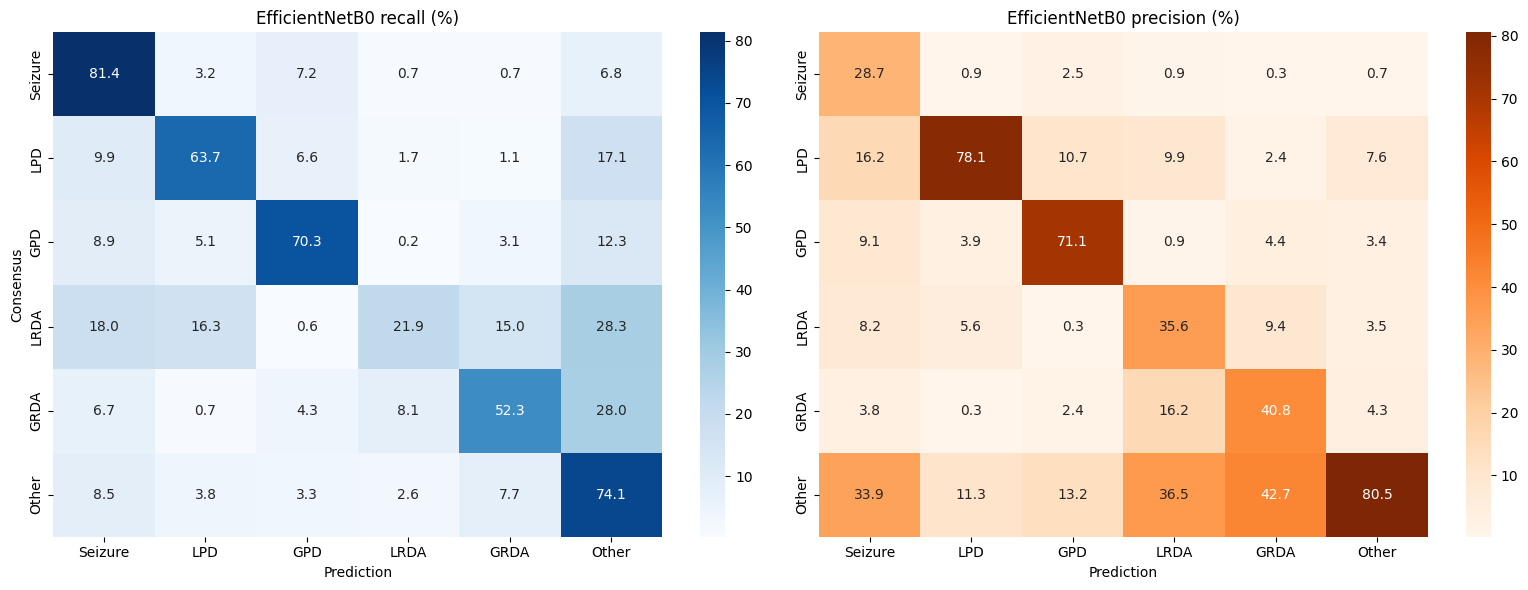

   Class |  AUROC |  Recall |    Prec
 Seizure | 0.937 |   81.4% |   28.7%
     LPD | 0.918 |   63.7% |   78.1%
     GPD | 0.950 |   70.3% |   71.1%
    LRDA | 0.850 |   21.9% |   35.6%
    GRDA | 0.907 |   52.3% |   40.8%
   Other | 0.874 |   74.1% |   80.5%


In [12]:
# Per-class metrics on the >=10-vote VIPEEGNet rows (same table format as the VIPEEGNet notebook)
if ROW_EVAL:
    import seaborn as sns
    from sklearn.metrics import confusion_matrix, roc_auc_score
    yti, ypi = yt_h.argmax(1), yp_h.argmax(1)
    ytb = (yti[:, None] == np.arange(6)).astype(int)
    cm = confusion_matrix(yti, ypi, labels=range(6))
    with np.errstate(invalid='ignore', divide='ignore'):
        cm_r = cm / cm.sum(1, keepdims=True) * 100; cm_p = cm / cm.sum(0, keepdims=True) * 100
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 6))
    sns.heatmap(cm_r, annot=True, fmt='.1f', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=a1)
    a1.set_title('EfficientNetB0 recall (%)'); a1.set_xlabel('Prediction'); a1.set_ylabel('Consensus')
    sns.heatmap(cm_p, annot=True, fmt='.1f', cmap='Oranges', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=a2)
    a2.set_title('EfficientNetB0 precision (%)'); a2.set_xlabel('Prediction')
    plt.tight_layout(); plt.savefig(f'{WDIR}/confusion.png', dpi=150); plt.show()
    print(f'{"Class":>8} | {"AUROC":>6} | {"Recall":>7} | {"Prec":>7}')
    for c, nm in enumerate(CLASS_NAMES):
        try:
            auc = roc_auc_score(ytb[:, c], yp_h[:, c])
        except ValueError:
            auc = float('nan')
        print(f'{nm:>8} | {auc:.3f} | {cm_r[c, c]:6.1f}% | {cm_p[c, c]:6.1f}%')